In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme()

Curatare

In [1]:
import pandas as pd, ast, re
df = pd.read_csv("../data/Goodreadss Books.csv")
df = df.drop(columns=["Unnamed: 0"])
df = df.dropna(subset=["title"])
df = df.sort_values("num_ratings", ascending=False)
df = df.drop_duplicates(subset=["title", "author"]).reset_index(drop=True)  

Format genuri

In [2]:
print(repr(df['genres'].iloc[0]))
print(type(df['genres'].iloc[0]))
df['genres'].head(5).tolist()

"Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Goodreads' Transgender Books page,Goodreads' Transgender Books page,Fantasy,Fiction,Young Adult,Fantasy,Magic,Childrens,Childrens,Middle Grade,Adventure,Classics,Audiobook,Science Fiction Fantasy"
<class 'str'>


["Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,Young Adult,Goodreads' Transgender Books page,Goodreads' Transgender Books page,Fantasy,Fiction,Young Adult,Fantasy,Magic,Childrens,Childrens,Middle Grade,Adventure,Classics,Audiobook,Science Fiction Fantasy",
 "Art,Biography,Business,Children's,Christian,Classics,Comics,Cookbooks,Ebooks,Fantasy,Fiction,Graphic Novels,Historical Fiction,History,Horror,Memoir,Music,Mystery,Nonfiction,Poetry,Psychology,Romance,Science,Science Fiction,Self Help,Sports,Thriller,Travel,You

OBS! Genurile arată ca text separat prin virgule, dar începutul șirului nu sunt genurile cărții. Primele 29 de genuri (de la Art la Young Adult) sunt lista de categorii din meniul Goodreads, copiată de două ori la scraping. Genurile reale ale cărții vin abia după ea: Fantasy, Fiction, Young Adult, Magic, Childrens, Middle Grade, Adventure, Classics, Audiobook, Science Fiction Fantasy. Mai apare și Goodreads' Transgender Books page, care e tot zgomot.

In [3]:
print(df['genres'].str.startswith("Art,Biography,Business").mean())

1.0


Genurile transformate in text curat (Historical Fiction devine Historical_Fiction, ca să rămână un singur token)

In [4]:
menu = df['genres'].dropna().iloc[0].split(",")[:29]   # blocul de 29 categorii din meniu

def clean_genres(x):
    if pd.isna(x): return ""
    g = [s.strip() for s in x.split(",")]
    while g[:len(menu)] == menu:          # scoate blocul, oricâte repetări ar fi
        g = g[len(menu):]
    g = [s for s in g if s and "Goodreads" not in s]
    return " ".join(dict.fromkeys(s.replace(" ", "_") for s in g))   # fără repetiții

df["genres_clean"] = df["genres"].apply(clean_genres)
print(df["genres_clean"].iloc[0])

Fantasy Fiction Young_Adult Magic Childrens Middle_Grade Adventure Classics Audiobook Science_Fiction_Fantasy


In [5]:
top_genres = df['genres_clean'].str.split().explode().value_counts().head(10)

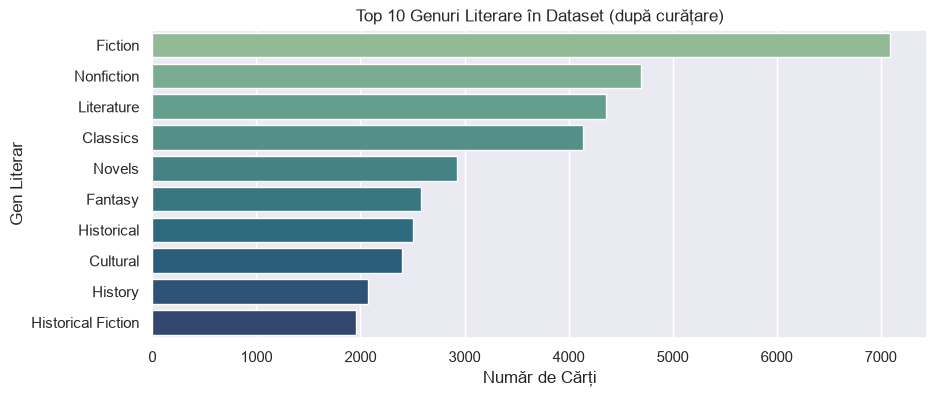

In [8]:
top_genres = df['genres_clean'].str.split().explode().value_counts().head(10)
top_genres.index = top_genres.index.str.replace("_", " ")   # Historical_Fiction -> Historical Fiction

plt.figure(figsize=(10, 4))
sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    hue=top_genres.index,
    palette='crest',
    legend=False
)
plt.title('Top 10 Genuri Literare în Dataset (după curățare)')
plt.xlabel('Număr de Cărți')
plt.ylabel('Gen Literar')
plt.show()

Textul pe care se face TF-IDF

In [9]:
for c in ["description", "author", "series", "title"]:
    df[c] = df[c].fillna("")
df["text"] = (df["title"] + " " + df["author"] + " " + df["series"] + " "
              + df["genres_clean"] + " " + df["genres_clean"] + " "   # genul de 2 ori = pondere mai mare
              + df["description"])

In [10]:
df["text"].iloc[0][:500]

"Harry Potter à l'école des sorciers J.K. Rowling,Jean-François Ménard Harry Potter #1 Fantasy Fiction Young_Adult Magic Childrens Middle_Grade Adventure Classics Audiobook Science_Fiction_Fantasy Fantasy Fiction Young_Adult Magic Childrens Middle_Grade Adventure Classics Audiobook Science_Fiction_Fantasy Le jour de ses onze ans, Harry Potter, un orphelin élevé par un oncle et une tante qui le détestent, voit son existence bouleversée. Un géant vient le chercher pour l'emmener à Poudlard, la célè"

TF-IDF

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2), min_df=2)
X = tfidf.fit_transform(df["text"])
print(X.shape)

(18126, 20000)


Functia de recomandare Python (cosine similarity)

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
titles = df["title"].str.lower()

def recommend(query, n=5):
    matches = df.index[titles.str.contains(query.lower(), regex=False)]
    if len(matches) == 0:
        return "Nicio carte găsită."
    idx = matches[0]                     # prima potrivire = cea mai populară (am sortat după num_ratings)
    sims = cosine_similarity(X[idx], X).ravel()
    top = sims.argsort()[::-1][1:n+1]
    return df.loc[top, ["title", "author", "avg_rating"]].assign(similaritate=sims[top].round(3))

In [15]:
recommend("harry potter")

,title,author,avg_rating,similaritate
49,Harry Potter et la Chambre des Secrets,J.K. Rowling,4.43,0.600
1,Harrius Potter et Philosophi Lapis,"J.K. Rowling,Peter Needham",4.48,0.554
5,Harry Potter Y La Piedra Filosofal,J.K. Rowling,4.48,0.554
2039,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling,Mary GrandPré",4.79,0.534
3,Harry Potter and the Philosopher's Stone,J.K. Rowling,4.48,0.487


In [16]:
recommend("the hobbit")

,title,author,avg_rating,similaritate
34,The Hobbit: Or There and Back Again,J.R.R. Tolkien,4.28,0.998
35,The Hobbit,"J.R.R. Tolkien,Paul Muldoon",4.28,0.598
37,The Hobbit,"J.R.R. Tolkien,Rob Inglis",4.28,0.511
38,"The Hobbit, or There and Back Again",J.R.R. Tolkien,4.28,0.402
36,The Annotated Hobbit,"J.R.R. Tolkien,Douglas A. Anderson",4.28,0.367


In [17]:
recommend("pride and prejudice")

,title,author,avg_rating,similaritate
26,The Annotated Pride & Prejudice,"Jane Austen,David M. Shapard",4.27,0.853
23,Pride and Prejudice,"Jane Austen,Anna Quindlen",4.27,0.565
28,Pride and Prejudice,"Jane Austen,Tony Tanner,Vivien Jones",4.27,0.561
22,Pride and Prejudice,"Jane Austen,Irene Sutcliffe",4.27,0.550
24,Pride & Prejudice,"Jane Austen,Vivien Jones",4.27,0.549


OBS: recomanda carti din aceeasi serie sau duplicate ale cartii in alta limba/editie

Voi curata duplicatele

In [18]:
df["main_author"] = df["author"].str.split(",").str[0].str.strip().str.lower()
df["title_norm"] = (df["title"].str.lower()
                    .str.replace("&", "and", regex=False)
                    .str.replace(r"\(.*?\)", "", regex=True)      # scoate (Harry Potter #1)
                    .str.split(r":|, or ", regex=True).str[0]     # scoate subtitlul
                    .str.replace(r"[^a-z0-9 ]", "", regex=True)
                    .str.strip())

In [19]:
def recommend(query, n=5):
    matches = df.index[titles.str.contains(query.lower(), regex=False)]
    if len(matches) == 0:
        return "Nicio carte găsită."
    idx = matches[0]
    sims = cosine_similarity(X[idx], X).ravel()

    seen = {(df.title_norm[idx], df.main_author[idx])}
    rows = []
    for j in sims.argsort()[::-1]:
        key = (df.title_norm[j], df.main_author[j])
        lang = df.language[j]
        if j == idx or key in seen:
            continue
        if pd.notna(lang) and lang != "English":      # fără traduceri
            continue
        seen.add(key)
        rows.append(j)
        if len(rows) == n:
            break
    return df.loc[rows, ["title", "author", "avg_rating"]].assign(similaritate=sims[rows].round(3))

In [20]:
recommend("harry potter")

,title,author,avg_rating,similaritate
2039,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling,Mary GrandPré",4.79,0.534
3,Harry Potter and the Philosopher's Stone,J.K. Rowling,4.48,0.487
15947,Harry Potter: The Final Challenge,Bookube,5.00,0.468
5815,Ultimate Unofficial Guide to the Mysteries of ...,"Galadriel Waters,Astre Mithrandir",4.05,0.437
6,Harry Potter and the Sorcerer's Stone,"J.K. Rowling,Mary GrandPré",4.48,0.425


In [21]:
recommend("the hobbit")

,title,author,avg_rating,similaritate
36,The Annotated Hobbit,"J.R.R. Tolkien,Douglas A. Anderson",4.28,0.367
1496,The Lord of the Rings / The Hobbit,J.R.R. Tolkien,4.60,0.334
1495,The Hobbit and The Lord of the Rings,J.R.R. Tolkien,4.60,0.334
1497,J.R.R. Tolkien 4-Book Boxed Set: The Hobbit an...,J.R.R. Tolkien,4.60,0.330
1494,The Hobbit ; The Fellowship of the Ring ; The ...,J.R.R. Tolkien,4.60,0.318


In [1]:
import sys; sys.path.append("..")
from src.recommender import Recommender
rec = Recommender("../data/Goodreadss Books.csv")
rec.by_title("harry potter")
rec.by_text("dark atmosphere detective murder mystery")

[{'title': 'The Curious Incident of the Dog in the Night-Time',
  'author': 'Mark Haddon',
  'rating': 3.89,
  'score': 0.225,
  'because': ['murder mystery', 'mystery', 'murder']},
 {'title': "Dead Man's Folly",
  'author': 'Agatha Christie',
  'rating': 3.82,
  'score': 0.214,
  'because': ['murder mystery', 'murder', 'detective']},
 {'title': 'Field of Thirteen',
  'author': 'Dick Francis',
  'rating': 3.74,
  'score': 0.208,
  'because': ['murder mystery', 'mystery', 'murder']},
 {'title': 'Swan Song',
  'author': 'Frank Fradella',
  'rating': 3.88,
  'score': 0.204,
  'because': ['murder mystery', 'murder', 'mystery']},
 {'title': 'Falling Angel',
  'author': 'William Hjortsberg,Ridley Scott,James Crumley',
  'rating': 3.92,
  'score': 0.197,
  'because': ['murder mystery', 'detective', 'mystery']}]

In [2]:
import sqlite3, pandas as pd
pd.read_sql("SELECT title, author, avg_rating FROM books LIMIT 5", sqlite3.connect("../data/books.db"))

,title,author,avg_rating
0,Harry Potter à l'école des sorciers,"J.K. Rowling,Jean-François Ménard",4.48
1,Harrius Potter et Philosophi Lapis,"J.K. Rowling,Peter Needham",4.48
2,Harry Potter y la piedra filosofal,"J.K. Rowling,Alicia Dellepiane Rawson,Dolores ...",4.48
3,Harry Potter and the Philosopher's Stone,J.K. Rowling,4.48
4,Harry Potter y la piedra filosofal,J.K. Rowling,4.48
